> **실험 기록.** 속도 모델 설계 과정의 비교 실험이며 출력은 실행 당시 결과를 보존했다. 최종 모델은 `src/models/`, 공식 성능은 [docs/SPEED_MODEL.md](../docs/SPEED_MODEL.md), 노트북별 요약과 재실행 조건은 [notebooks/README.md](README.md)에 있다.

# Speed Prediction — Baseline Model (5분 데이터 기준)

5분 단위 전국 교통소통 데이터로 매칭된 링크(44,960개, 70.75%)의 `평균속도`를 예측하는 베이스라인입니다.

**범위**: 최종 결합 테이블(`seoul_link_speed_dem_weather_merged.csv`, 42컬럼) 중 도로 속성/지형/강수 원본 수치형·범주형 피처만 사용합니다. 요일·주말·시간 순환 인코딩 같은 파생 피처는 다음 단계에서 하나씩 추가하며 이 노트북의 결과와 비교합니다.

**입력**: `data/processed/seoul_link_speed_dem_weather_merged.csv` (15,094,335행)
**타깃**: `평균속도`

**이전 버전과의 차이**: 이전 T-data 기반 노트북은 하나의 소스 관측이 여러 형제 링크에 속도값을 복제(broadcast)하는 구조 때문에 `LINK_ID` 앞 8자리 기준 그룹 분할이 필요했습니다. 5분 데이터는 `source_observation_id`(`LINK_ID_기준일_시간코드`)가 행마다 고유해 복제가 없으므로, 이 노트북은 일반 무작위 분할을 사용합니다(근거는 2번 섹션 참고).

In [1]:
from pathlib import Path

import catboost as cb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Jupyter 실행 위치가 notebooks/ 폴더라고 가정합니다 (jupyter lab/notebook 기본 동작).
PROJECT_ROOT = Path.cwd().parent
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
DOCS_FIGURES_DIR = PROJECT_ROOT / "docs" / "figures" / "model"
DOCS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

INPUT_PATH = PROCESSED_DATA_DIR / "seoul_link_speed_dem_weather_merged.csv"

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42

# 검증된 카테고리컬 팔레트(dataviz 팔레트 slot 1/2)에서 2개 시리즈(RMSE/MAE)용 색만 가져옵니다.
COLOR_RMSE = "#2a78d6"   # slot 1 blue
COLOR_MAE = "#eb6834"    # slot 2 orange
COLOR_SEQ = "#3987e5"    # sequential blue, mid step (단일 시리즈용)


## 1. 피처 정의와 로드

최종 테이블 42컬럼 중 아래 기준으로 골랐습니다.

**사용**

| 유형 | 컬럼 |
| --- | --- |
| 수치형 (14) | `LANES`, `MAX_SPD`, `LENGTH`, `시간코드`, `elev_start_m`, `elev_mid_m`, `elev_end_m`, `elev_mean_m`, `elev_min_m`, `elev_max_m`, `elev_delta_m`, `slope_pct`, `abs_slope_pct`, `precip_mm` |
| 범주형 (9) | `ROAD_RANK`, `ROAD_TYPE`, `ROAD_USE`, `MULTI_LINK`, `CONNECT`, `REST_VEH`, `REST_W`, `REST_H`, `C-ITS` |

**제외 (이유)**

| 컬럼 | 제외 이유 |
| --- | --- |
| `UPDATEDATE`, `REMARK`, `HIST_TYPE`, `HISTREMARK` | 메타데이터, 예측과 무관 |
| `match_method` | 전 행 `5min_direct` 단일값, 정보량 0 |
| `sample_weight` | 전 행 `1.0` 단일값, 정보량 0 |
| `source_section_id` | `LINK_ID`와 100% 동일값, 중복 |
| `source_observation_id` | 사실상 행 고유 ID(`LINK_ID_기준일_시간코드`) — 그대로 넣으면 유출 |
| `radar_raw_value` | `precip_mm`으로 이미 정제된 값, 중복 |
| `tm` | `기준일`+`시간코드`로 이미 표현, 중복 |
| `ROAD_NO`, `ROAD_NAME`, `F_NODE`, `T_NODE` | 고카디널리티 식별자 — 도로 자체를 암기하는 과적합 위험 |
| `dem_sample_count` | 15,094,335행 전부 `5` — 분산 없음, 정보량 0 (사전 확인 완료) |
| `LINK_ID` | 도로 자체를 암기하는 과적합 위험 + 그룹 분할을 쓰지 않는 이번 베이스라인에는 진단 용도도 없어 아예 로드하지 않음 |
| `기준일` | 원본 그대로는 카디널리티 14짜리 날짜 식별자 — 파생 피처(요일/주말)로 다음 단계에서 대체 예정, 이번 베이스라인에서는 아예 미사용 |
| `sample_count_5min` | 라벨 신뢰도 가중치 후보 — 이번 베이스라인에서는 미사용, 다음 단계에서 검토 |

In [2]:
NUMERIC_COLS = [
    "LANES", "MAX_SPD", "LENGTH", "시간코드",
    "elev_start_m", "elev_mid_m", "elev_end_m", "elev_mean_m", "elev_min_m", "elev_max_m", "elev_delta_m",
    "slope_pct", "abs_slope_pct", "precip_mm",
]
CATEGORICAL_COLS = [
    "ROAD_RANK", "ROAD_TYPE", "ROAD_USE", "MULTI_LINK", "CONNECT",
    "REST_VEH", "REST_W", "REST_H", "C-ITS",
]
TARGET = "평균속도"

# LINK_ID는 로드하지 않습니다 — 이번 베이스라인은 그룹 분할을 쓰지 않아(3번 섹션 근거)
# 피처로도 진단용으로도 쓸 데가 없고, 1,500만 행짜리 문자열 컬럼을 메모리에 얹기만 합니다.
usecols = NUMERIC_COLS + CATEGORICAL_COLS + [TARGET]
dtype_map = {col: str for col in CATEGORICAL_COLS}

df = pd.read_csv(INPUT_PATH, usecols=usecols, dtype=dtype_map, encoding="utf-8-sig")

for col in NUMERIC_COLS + [TARGET]:
    df[col] = pd.to_numeric(df[col], errors="coerce").astype("float32")

# LightGBM은 컬럼명에 JSON 특수문자(하이픈 등)를 문제 삼는 경우가 있어
# 해당 컬럼만 모델링용 이름으로 바꿉니다(의미·값은 동일).
RENAME_MAP = {"C-ITS": "c_its"}
df = df.rename(columns=RENAME_MAP)
CATEGORICAL_COLS = [RENAME_MAP.get(c, c) for c in CATEGORICAL_COLS]

print("행 수:", len(df))
print("컬럼 수:", df.shape[1])
print("메모리 사용량(MB):", round(df.memory_usage(deep=True).sum() / 1e6, 1))
df.head()


행 수: 15094335
컬럼 수: 24
메모리 사용량(MB): 2160.3


,시간코드,평균속도,LANES,ROAD_RANK,ROAD_TYPE,ROAD_USE,MULTI_LINK,CONNECT,MAX_SPD,REST_VEH,...,elev_start_m,elev_mid_m,elev_end_m,elev_mean_m,elev_min_m,elev_max_m,elev_delta_m,slope_pct,abs_slope_pct,precip_mm
0,1.0,13.166667,2.0,103,0,0,1,0,50.0,0,...,29.623407,29.623407,29.623407,29.623407,29.623407,29.623407,0.0,0.0,0.0,0.0
1,2.0,16.250000,2.0,103,0,0,1,0,50.0,0,...,29.623407,29.623407,29.623407,29.623407,29.623407,29.623407,0.0,0.0,0.0,0.0
2,3.0,14.000000,2.0,103,0,0,1,0,50.0,0,...,29.623407,29.623407,29.623407,29.623407,29.623407,29.623407,0.0,0.0,0.0,0.0
3,4.0,15.000000,2.0,103,0,0,1,0,50.0,0,...,29.623407,29.623407,29.623407,29.623407,29.623407,29.623407,0.0,0.0,0.0,0.0
4,5.0,15.250000,2.0,103,0,0,1,0,50.0,0,...,29.623407,29.623407,29.623407,29.623407,29.623407,29.623407,0.0,0.0,0.0,0.0


## 2. 결측치 확인 및 전처리

In [3]:
missing = df[NUMERIC_COLS + CATEGORICAL_COLS + [TARGET]].isna().sum()
missing = missing[missing > 0]
print("결측 존재 컬럼:")
print(missing if len(missing) else "없음")

before = len(df)
df = df.dropna(subset=[TARGET] + NUMERIC_COLS)
print(f"결측 제거: {before}행 -> {len(df)}행")

for col in CATEGORICAL_COLS:
    df[col] = df[col].astype("category")


결측 존재 컬럼:
없음


결측 제거: 15094335행 -> 15094335행


## 3. Train/Test 분할

5분 데이터는 `source_observation_id`(`LINK_ID`+`기준일`+`시간코드`)가 행마다 고유해서 T-data처럼 같은 관측이 여러 행에 복제되는 구조가 없습니다. 날짜별 평균속도도 요일이 같은 날짜끼리 비교했을 때 강수량이 0~14mm까지 크게 달라도 평균속도 차이는 0.11~0.88km/h에 그쳐, 특정 날짜의 이례적 사건이 전체 패턴을 흔드는 정도가 크지 않음을 확인했습니다. 그래서 이번 베이스라인은 별도 그룹/날짜 분할 없이 **일반 무작위 80/20 분할**을 사용합니다.

In [4]:
import gc

FEATURE_COLS = NUMERIC_COLS + CATEGORICAL_COLS
X = df[FEATURE_COLS]
y = df[TARGET]
del df  # X/y로 필요한 컬럼만 복사됐으니 원본 df(타깃 포함 전체 컬럼)는 더 안 들고 있어도 됨
gc.collect()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
del X, y  # 분할 후에는 원본도 불필요 — 뒤에서 3개 모델을 순서대로 학습하므로 피크 메모리를 미리 줄여둠
gc.collect()

print("train/test 행 수:", len(X_train), len(X_test))


train/test 행 수: 12075468 3018867


## 4. 베이스라인

1. **전체 평균**: 아무 피처도 안 쓰고 train 평균속도로만 예측
2. **MAX_SPD 선형회귀**: 단일 변수만 사용
3. **ROAD_RANK별 평균**: 도로등급 7종의 train 평균속도로 예측

In [5]:
def evaluate(y_true, y_pred, name):
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {"model": name, "rmse": rmse, "mae": mae, "r2": r2}


results = []

dummy = DummyRegressor(strategy="mean").fit(X_train[["LENGTH"]], y_train)
pred = dummy.predict(X_test[["LENGTH"]])
results.append(evaluate(y_test, pred, "전체 평균"))

lin = LinearRegression().fit(X_train[["MAX_SPD"]], y_train)
pred = lin.predict(X_test[["MAX_SPD"]])
results.append(evaluate(y_test, pred, "MAX_SPD 선형회귀"))

rank_mean = y_train.groupby(X_train["ROAD_RANK"], observed=True).mean()
pred = X_test["ROAD_RANK"].map(rank_mean).fillna(y_train.mean())
results.append(evaluate(y_test, pred, "ROAD_RANK별 평균"))

pd.DataFrame(results)


,model,rmse,mae,r2
0,전체 평균,12.256461,8.542620,-1.192093e-07
1,MAX_SPD 선형회귀,11.151336,8.116281,1.722032e-01
2,ROAD_RANK별 평균,10.499088,7.644192,2.662079e-01


## 5. 모델 비교 — LightGBM / XGBoost / CatBoost

같은 피처·같은 분할로 세 가지 그래디언트 부스팅 구현체를 비교합니다. 모두 범주형 컬럼을 원-핫 없이 네이티브로 처리합니다.

In [6]:
lgb_model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=63,
    random_state=RANDOM_STATE,
    verbosity=-1,
)
lgb_model.fit(X_train, y_train, categorical_feature=CATEGORICAL_COLS)
pred_lgb = lgb_model.predict(X_test)
results.append(evaluate(y_test, pred_lgb, "LightGBM"))
gc.collect()
results[-1]


{'model': 'LightGBM',
 'rmse': 7.652966670997528,
 'mae': 5.764899686592482,
 'r2': 0.6101212805788272}

In [7]:
xgb_model = xgb.XGBRegressor(
    objective="reg:squarederror",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=8,
    tree_method="hist",
    enable_categorical=True,
    random_state=RANDOM_STATE,
)
xgb_model.fit(X_train, y_train)
pred_xgb = xgb_model.predict(X_test)
results.append(evaluate(y_test, pred_xgb, "XGBoost"))
gc.collect()
results[-1]


{'model': 'XGBoost',
 'rmse': 7.436169930144178,
 'mae': 5.583755970001221,
 'r2': 0.6318976879119873}

In [8]:
# CatBoost는 pandas category dtype을 그대로 받아들이므로(사전 검증 완료)
# LightGBM/XGBoost 때와 달리 컬럼을 문자열로 바꿔 복사할 필요가 없습니다.
# (X_train/X_test 전체를 복제하면 1,200만 행 x 23컬럼이 통째로 두 번 더 메모리에 올라가
#  이 환경의 여유 메모리로는 감당이 안 됨 — 실제로 이전 버전에서 이 복제 때문에 메모리가 바닥났습니다.)
cb_model = cb.CatBoostRegressor(
    iterations=300,
    learning_rate=0.05,
    depth=8,
    cat_features=CATEGORICAL_COLS,
    random_state=RANDOM_STATE,
    verbose=False,
)
cb_model.fit(X_train, y_train)
pred_cb = cb_model.predict(X_test)
results.append(evaluate(y_test, pred_cb, "CatBoost"))
results[-1]


{'model': 'CatBoost',
 'rmse': 8.162448626673061,
 'mae': 6.065318289119456,
 'r2': 0.5564824507566899}

In [9]:
results_df = pd.DataFrame(results)
results_df


,model,rmse,mae,r2
0,전체 평균,12.256461,8.542620,-1.192093e-07
1,MAX_SPD 선형회귀,11.151336,8.116281,1.722032e-01
2,ROAD_RANK별 평균,10.499088,7.644192,2.662079e-01
3,LightGBM,7.652967,5.764900,6.101213e-01
4,XGBoost,7.436170,5.583756,6.318977e-01
5,CatBoost,8.162449,6.065318,5.564825e-01


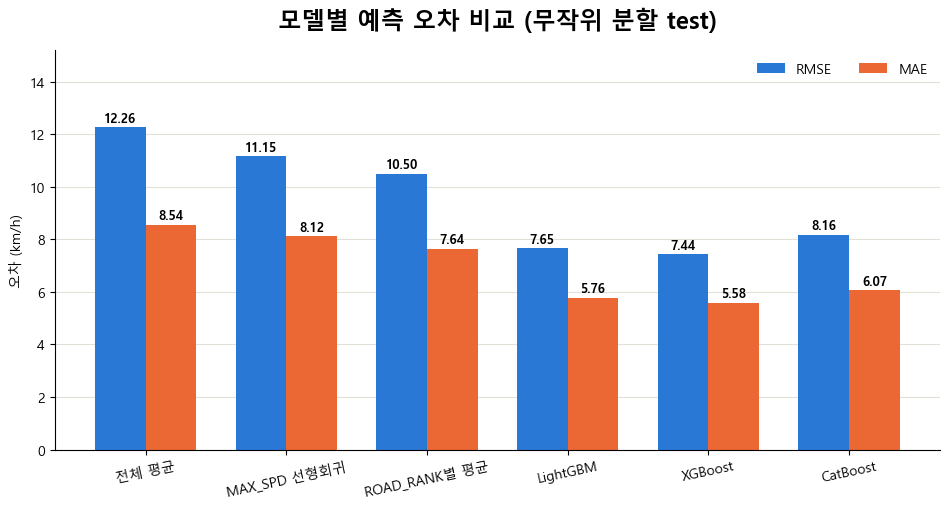

저장: docs\figures\model\01_model_comparison.png


In [10]:
labels = results_df["model"].tolist()
x = range(len(labels))
width = 0.36

fig, ax = plt.subplots(figsize=(9.6, 5.2))
ax.bar([i - width / 2 for i in x], results_df["rmse"], width, label="RMSE", color=COLOR_RMSE)
ax.bar([i + width / 2 for i in x], results_df["mae"], width, label="MAE", color=COLOR_MAE)
ax.set_xticks(list(x), labels, rotation=12)
ax.set_title("모델별 예측 오차 비교 (무작위 분할 test)", fontsize=17, fontweight="bold", pad=16)
ax.set_ylabel("오차 (km/h)")
ax.legend(frameon=False, ncols=2, loc="upper right")

for patch in ax.patches:
    height = patch.get_height()
    ax.text(patch.get_x() + patch.get_width() / 2, height + 0.1, f"{height:.2f}",
            ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
top = ax.get_ylim()[1]
ax.set_ylim(0, top * 1.18)
fig.tight_layout()
fig.savefig(DOCS_FIGURES_DIR / "01_model_comparison.png", dpi=220, bbox_inches="tight")
plt.show()
print("저장:", DOCS_FIGURES_DIR / "01_model_comparison.png")


## 6. 피처 중요도 (최고 성능 모델)

세 모델 중 RMSE가 가장 낮은 모델을 기준으로 어떤 원본 컬럼이 예측에 기여하는지 확인합니다. 다음 단계에서 어떤 파생 피처를 추가할지 우선순위를 정하는 데 사용합니다.

최고 성능 모델: XGBoost


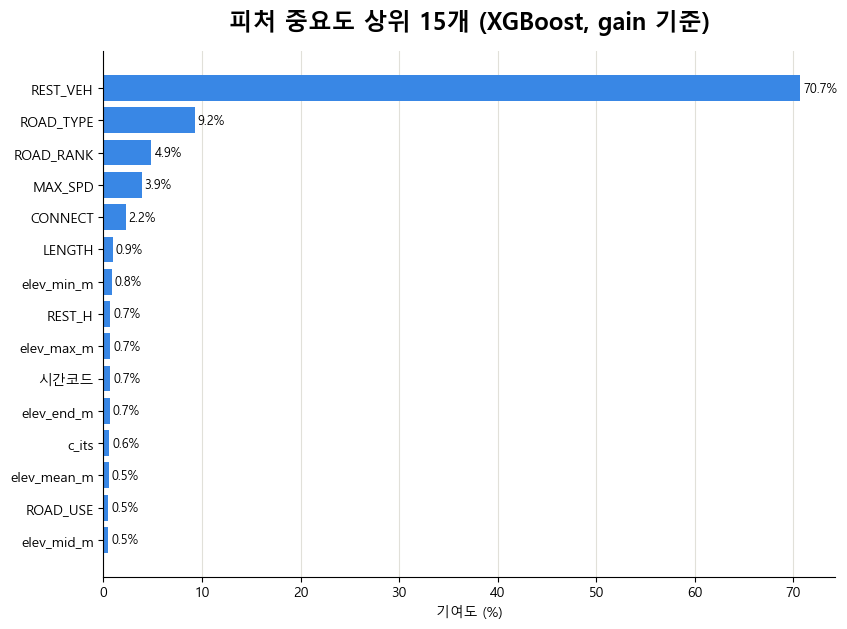

저장: docs\figures\model\02_feature_importance.png


,feature,gain,gain_share
19,REST_VEH,8.572144e+06,0.707088
15,ROAD_TYPE,1.120236e+06,0.092405
14,ROAD_RANK,5.902719e+05,0.048690
1,MAX_SPD,4.707696e+05,0.038832
18,CONNECT,2.717699e+05,0.022417
2,LENGTH,1.113070e+05,0.009181
8,elev_min_m,1.015474e+05,0.008376
21,REST_H,8.596906e+04,0.007091
9,elev_max_m,8.225010e+04,0.006785
3,시간코드,8.126704e+04,0.006703


In [11]:
best_row = results_df.loc[results_df["rmse"].idxmin()]
best_name = best_row["model"]
print("최고 성능 모델:", best_name)

if best_name == "LightGBM":
    importance = pd.DataFrame({
        "feature": lgb_model.feature_name_,
        "gain": lgb_model.booster_.feature_importance(importance_type="gain"),
    })
elif best_name == "XGBoost":
    booster = xgb_model.get_booster()
    score = booster.get_score(importance_type="gain")
    importance = pd.DataFrame({
        "feature": list(score.keys()),
        "gain": list(score.values()),
    })
else:
    importance = pd.DataFrame({
        "feature": FEATURE_COLS,
        "gain": cb_model.get_feature_importance(),
    })

importance = importance.sort_values("gain", ascending=False)
importance["gain_share"] = importance["gain"] / importance["gain"].sum()

top_n = 15
plot_df = importance.head(top_n).sort_values("gain")

fig, ax = plt.subplots(figsize=(8.6, 6.4))
ax.barh(plot_df["feature"], plot_df["gain_share"] * 100, color=COLOR_SEQ)
ax.set_title(f"피처 중요도 상위 {top_n}개 ({best_name}, gain 기준)", fontsize=17, fontweight="bold", pad=16)
ax.set_xlabel("기여도 (%)")

for patch in ax.patches:
    width = patch.get_width()
    ax.text(width + 0.3, patch.get_y() + patch.get_height() / 2, f"{width:.1f}%",
            va="center", fontsize=9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(DOCS_FIGURES_DIR / "02_feature_importance.png", dpi=220, bbox_inches="tight")
plt.show()
print("저장:", DOCS_FIGURES_DIR / "02_feature_importance.png")

importance.head(top_n)


## 7. 예측값 vs 실제값 (최고 성능 모델)

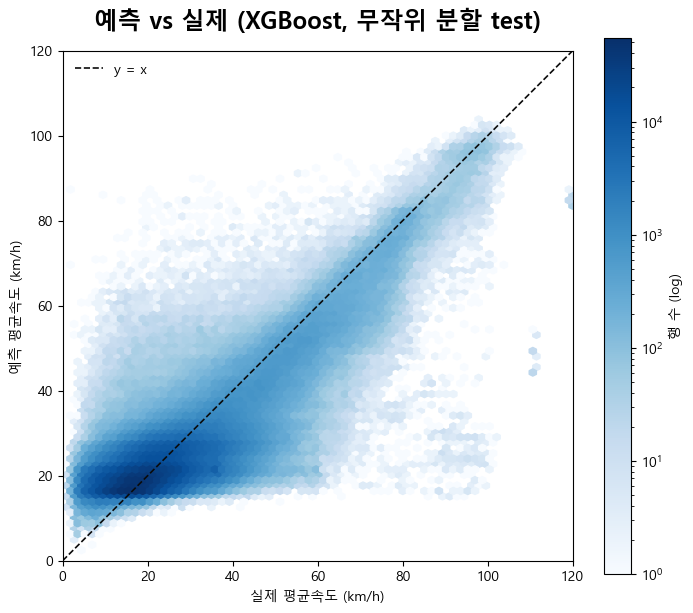

저장: docs\figures\model\03_predicted_vs_actual.png


In [12]:
pred_map = {"LightGBM": pred_lgb, "XGBoost": pred_xgb, "CatBoost": pred_cb}
best_pred = pred_map[best_name]

fig, ax = plt.subplots(figsize=(7.2, 7.0))
hb = ax.hexbin(y_test, best_pred, gridsize=70, cmap="Blues", mincnt=1, bins="log")
lims = [0, max(y_test.max(), best_pred.max())]
ax.plot(lims, lims, color="#0b0b0b", linewidth=1.2, linestyle="--", label="y = x")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("실제 평균속도 (km/h)")
ax.set_ylabel("예측 평균속도 (km/h)")
ax.set_title(f"예측 vs 실제 ({best_name}, 무작위 분할 test)", fontsize=17, fontweight="bold", pad=16)
ax.legend(frameon=False, loc="upper left")
cb_ = fig.colorbar(hb, ax=ax, shrink=0.8)
cb_.set_label("행 수 (log)")
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(DOCS_FIGURES_DIR / "03_predicted_vs_actual.png", dpi=220, bbox_inches="tight")
plt.show()
print("저장:", DOCS_FIGURES_DIR / "03_predicted_vs_actual.png")


## 요약

In [13]:
print("=== 모델 비교 (무작위 분할 test) ===")
print(results_df.round(3).to_string(index=False))
print()
print("=== 피처 중요도 상위 5개 ({}) ===".format(best_name))
print(importance.head(5)[["feature", "gain_share"]].round(4).to_string(index=False))


=== 모델 비교 (무작위 분할 test) ===
        model   rmse   mae     r2
        전체 평균 12.256 8.543 -0.000
 MAX_SPD 선형회귀 11.151 8.116  0.172
ROAD_RANK별 평균 10.499 7.644  0.266
     LightGBM  7.653 5.765  0.610
      XGBoost  7.436 5.584  0.632
     CatBoost  8.162 6.065  0.556

=== 피처 중요도 상위 5개 (XGBoost) ===
  feature  gain_share
 REST_VEH      0.7071
ROAD_TYPE      0.0924
ROAD_RANK      0.0487
  MAX_SPD      0.0388
  CONNECT      0.0224


이 결과는 **42컬럼 중 원본 수치형·범주형 피처만으로 만든 첫 베이스라인**입니다(`요일`, `주말`, 시간 순환 인코딩 등 파생 피처는 아직 없음).

**다음 단계**: 이 피처 중요도 순위를 참고해 파생 피처를 하나씩 추가하면서, 매번 이 노트북과 동일한 무작위 분할 기준으로 RMSE/MAE가 실제로 개선되는지 확인합니다. 개선폭이 없는 파생 피처는 채택하지 않고, 있는 것만 남기는 방식으로 진행합니다.

이 결과는 인과관계 검증이 아니라 예측 성능 검증입니다.